# Figure 2: Package landscape

Compare 2025 Europe PMC counts across the 30 registry packages and calculate each package's 2020-to-2025 fold change. The figure marks changes from fewer than 20 starting papers as fragile. See `MANUSCRIPT/01_MAIN.md`, Introduction, Figure 2 caption, and Methods, Package registry and queries.

All figure walkthroughs use the shared Matplotlib 3.11.2 publication renderer through the bioimage-figures kernel.


In [1]:
from pathlib import Path
import sys
from tempfile import TemporaryDirectory

import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib import image as mpimg
import matplotlib.pyplot as plt

cwd = Path.cwd().resolve()
REPO_ROOT = next((p for p in (cwd, *cwd.parents) if (p / 'scripts' / 'census' / '_registry.py').is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError('Could not locate scripts/census/_registry.py from the notebook working directory')
SCRIPTS_DIR = REPO_ROOT / 'scripts'
FIGURES_DIR = SCRIPTS_DIR / 'census' / 'figures'
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from census._registry import build_boolean_query, load_registry
from census.figures import fig2_landscape as figure
from census.figures import style as fs

reg = load_registry()
def inspect_processed(name, columns=None):
    frame = fs.load(name)
    print(f'{name}: shape={frame.shape}')
    display((frame if columns is None else frame[columns]).head())
    return frame

## Registry and query construction

`_registry.load_registry()` supplies the aliases, scope, aggregate flag, and shared microscopy context. `build_boolean_query()` assembles the alias clause and context; yearly counts add the year restriction.


In [2]:
registry_table = pd.DataFrame([
    {'tool_id': tool.id, 'name': tool.name, 'category': tool.category, 'scope': tool.scope,
     'in_aggregate': tool.in_aggregate, 'aliases': ' | '.join(tool.aliases),
     'query': build_boolean_query(tool, reg.context_query)}
    for tool in reg.tools
])
print(f'{len(reg.tools)} packages; years {reg.year_start}-{reg.year_end}')
print(f'Shared context: {reg.context_query}')
print(f'Registry table shape: {registry_table.shape}')
display(registry_table.drop(columns='query').head(8))
display(registry_table.loc[registry_table.tool_id.isin(['imagej', 'qupath', 'cellprofiler', 'napari']), ['tool_id', 'aliases', 'query']])

30 packages; years 2010-2025
Shared context: (microscopy OR microscope) AND HAS_FT:Y
Registry table shape: (30, 7)


,tool_id,name,category,scope,in_aggregate,aliases
0,jupyter,Jupyter notebooks,notebook,core,False,Jupyter | Jupyter notebook | IPython notebook
1,imagej,ImageJ / Fiji,general-platform,core,True,ImageJ | ImageJ2 | Fiji | FIJI
2,napari,napari,general-platform,core,True,napari
3,cellprofiler,CellProfiler,general-platform,core,True,CellProfiler
4,qupath,QuPath,general-platform,core,True,QuPath
5,icy,Icy,general-platform,core,True,Icy bioimage | Icy software | de Chaumont Icy
6,ilastik,ilastik,general-platform,core,True,ilastik
7,knime,KNIME,general-platform,core,True,KNIME


,tool_id,aliases,query
1,imagej,ImageJ | ImageJ2 | Fiji | FIJI,"(""ImageJ2"" OR ""ImageJ"" OR ""Fiji"" OR ""FIJI"") AN..."
2,napari,napari,"""napari"" AND ((microscopy OR microscope) AND H..."
3,cellprofiler,CellProfiler,"""CellProfiler"" AND ((microscopy OR microscope)..."
4,qupath,QuPath,"""QuPath"" AND ((microscopy OR microscope) AND H..."


In [3]:
inspect_processed('tools.csv')
literature_all = inspect_processed('literature_yearly.csv')
inspect_processed('corpus_yearly.csv')

tools.csv: shape=(30, 7)


,tool_id,name,category,implies_dl,in_aggregate,scope,homepage
0,jupyter,Jupyter notebooks,notebook,False,False,core,https://jupyter.org
1,imagej,ImageJ / Fiji,general-platform,False,True,core,https://imagej.net
2,napari,napari,general-platform,False,True,core,https://napari.org
3,cellprofiler,CellProfiler,general-platform,False,True,core,https://cellprofiler.org
4,qupath,QuPath,general-platform,False,True,core,https://qupath.github.io


literature_yearly.csv: shape=(960, 4)


,source,tool_id,year,count
0,openalex,jupyter,2010,0
1,openalex,jupyter,2011,0
2,openalex,jupyter,2012,0
3,openalex,jupyter,2013,0
4,openalex,jupyter,2014,0


corpus_yearly.csv: shape=(16, 2)


,year,microscopy_papers
0,2010,42806
1,2011,49532
2,2012,58343
3,2013,66112
4,2014,70986


,year,microscopy_papers
0,2010,42806
1,2011,49532
2,2012,58343
3,2013,66112
4,2014,70986
5,2015,78337
6,2016,84586
7,2017,94060
8,2018,100986
9,2019,112489


## Counts, ranks, and fold changes

The figure uses Europe PMC counts for 2025 and divides those counts by the corresponding 2020 counts. Its aggregate group follows the registry flag; MATLAB and Jupyter notebooks remain scale references. A zero 2020 count has no finite fold change.


In [4]:
lit = fs.europepmc_yearly()
wide = lit.pivot(index='tool_id', columns='year', values='count').fillna(0)
landscape = registry_table.set_index('tool_id')[['name', 'category', 'scope', 'in_aggregate']].join(wide)
landscape['count_2020'] = landscape[2020]
landscape['count_2025'] = landscape[2025]
landscape['fold_change'] = landscape['count_2025'].div(landscape['count_2020'].replace(0, np.nan))
landscape['fragile_base'] = landscape['count_2020'] < 20
ranked = landscape.sort_values('count_2025', ascending=False)
print(f'Ranked table shape: {ranked.shape}')
display(ranked[['name', 'category', 'scope', 'count_2020', 'count_2025', 'fold_change', 'fragile_base']].head(12))

analysis = fs.analysis_tools()
ranked_analysis = landscape.loc[analysis].sort_values('count_2025', ascending=False)
next_tool = ranked_analysis.iloc[1]
ratio = ranked_analysis.iloc[0]['count_2025'] / next_tool['count_2025']
print('ImageJ/Fiji has {:.1f} times the 2025 matches of {}.'.format(ratio, next_tool['name']))
shares = fs.share_of_total('analysis')
display(shares.loc[(shares.tool_id.eq('imagej')) & shares.year.isin([2010, 2020, 2025]), ['tool_id', 'year', 'share']])

Ranked table shape: (30, 24)


,name,category,scope,count_2020,count_2025,fold_change,fragile_base
tool_id,,,,,,,
imagej,ImageJ / Fiji,general-platform,core,29768,49255,1.654629,False
matlab,MATLAB,commercial,core,6136,7331,1.194752,False
zen,ZEN,acquisition-suite,counts,2557,3859,1.509190,False
nis,NIS-Elements,acquisition-suite,counts,2643,3195,1.208854,False
lasx,LAS X,acquisition-suite,counts,1856,2761,1.487608,False
imaris,Imaris,commercial,core,1961,2744,1.399286,False
qupath,QuPath,general-platform,core,159,1625,10.220126,False
cellsens,cellSens,acquisition-suite,counts,992,1352,1.362903,False
cellprofiler,CellProfiler,general-platform,core,544,1032,1.897059,False


ImageJ/Fiji has 18.0 times the 2025 matches of Imaris.


,tool_id,year,share
16,imagej,2010,79.871406
26,imagej,2020,85.300017
31,imagej,2025,82.135472


## Optional processed-table rebuild from cached Europe PMC responses

Set `REBUILD = True` to reconstruct Europe PMC yearly counts and the microscopy denominator with the pipeline collection functions. A cache-only reader raises on missing responses, so this cell cannot fetch data. It writes comparison CSVs in a temporary folder and leaves `data/processed` unchanged. Repository-star and package-download snapshots remain the saved observations.


In [5]:
REBUILD = False
if REBUILD:
    import json
    from unittest.mock import patch
    from census import _http
    from census.sources import europepmc

    def cached_json(source, url, params=None, **kwargs):
        cache = _http._cache_path(source, url, params)
        if not cache.is_file():
            raise FileNotFoundError(f'Missing cached response: {cache.name}; no request was sent')
        return json.loads(cache.read_text())

    with patch.object(europepmc, 'get_json', cached_json):
        rebuilt_counts = pd.DataFrame(europepmc.collect_yearly(reg))
        rebuilt_corpus = pd.DataFrame(europepmc.corpus_yearly(reg))
    pd.testing.assert_frame_equal(rebuilt_counts.reset_index(drop=True), fs.europepmc_yearly().assign(source='europepmc')[rebuilt_counts.columns].reset_index(drop=True))
    pd.testing.assert_frame_equal(rebuilt_corpus, fs.load('corpus_yearly.csv'))
    with TemporaryDirectory(prefix='cached-processed-rebuild-') as output_dir:
        rebuilt_counts.to_csv(Path(output_dir) / 'literature_europepmc_yearly.csv', index=False)
        rebuilt_corpus.to_csv(Path(output_dir) / 'corpus_yearly.csv', index=False)
        print(f'Cached tables match: counts {rebuilt_counts.shape}, corpus {rebuilt_corpus.shape}')


## Render and compare

The final cell uses `style.save` for the notebook build, calls the module's `main(out_dir=...)` in a second temporary directory, compares the PNG arrays, and displays a scaled preview.


wrote Figure2__landscape.png/.pdf/.svg


wrote Figure2__landscape.png/.pdf/.svg
PNG shape: (1264, 1668, 4); mean absolute pixel difference: 0.000000


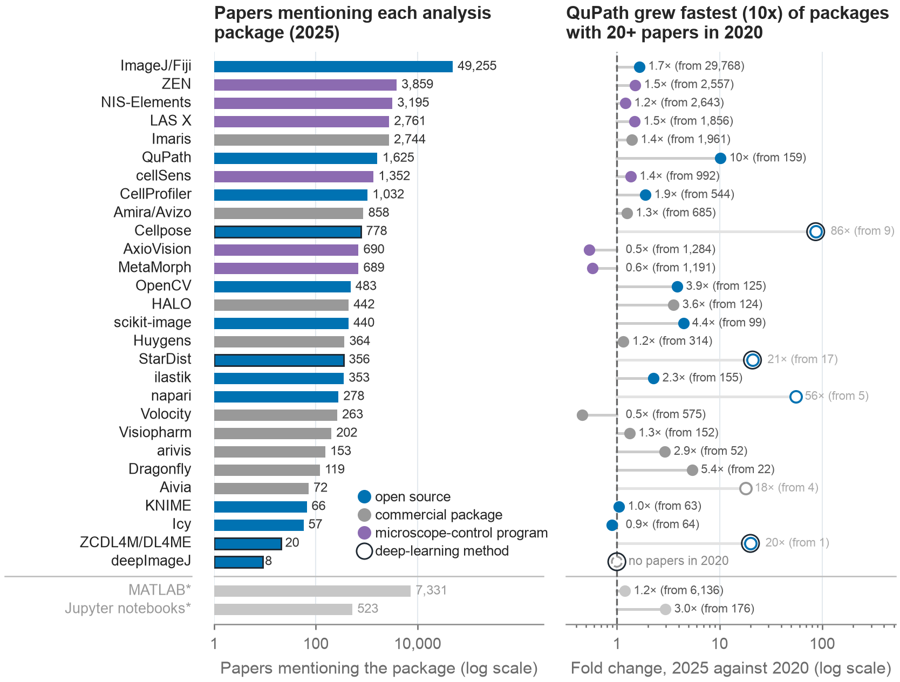

In [6]:
OUTPUT_STEM = 'Figure2__landscape'
fig = figure.build_figure()
with TemporaryDirectory(prefix='figure2-notebook-') as notebook_dir, TemporaryDirectory(prefix='figure2-module-') as module_dir:
    fs.save(fig, OUTPUT_STEM, out_dir=notebook_dir)
    figure.main(out_dir=module_dir)
    notebook_png = Path(notebook_dir) / f'{OUTPUT_STEM}.png'
    module_png = Path(module_dir) / f'{OUTPUT_STEM}.png'
    notebook_image = mpimg.imread(notebook_png)
    module_image = mpimg.imread(module_png)
    assert notebook_image.shape == module_image.shape, (notebook_image.shape, module_image.shape)
    np.testing.assert_array_equal(notebook_image, module_image)
    print(f'PNG shape: {notebook_image.shape}; mean absolute pixel difference: {np.abs(notebook_image - module_image).mean():.6f}')
    from io import BytesIO
    from PIL import Image as PILImage
    preview = PILImage.open(notebook_png)
    preview.thumbnail((900, 900))
    preview_bytes = BytesIO()
    preview.save(preview_bytes, format='PNG')
    display(Image(data=preview_bytes.getvalue(), width=min(640, preview.width)))
plt.close('all')